In [2]:
import json, re, time, warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import requests
import matplotlib.pyplot as plt
from matplotlib.path import Path as MplPath
from scipy.interpolate import RegularGridInterpolator
import astropy.units as u
from astropy import log
from astropy.coordinates import SkyCoord, Distance
from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from astropy.table import Table, vstack
from astropy.time import Time
from astropy.wcs import WCS
from astroquery.ipac.irsa import Irsa
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry
from pyvo.dal import DALServiceError

from app.config import get_settings

cfg = get_settings()
log.setLevel("WARNING")           # hide the SIP INFO message
warnings.simplefilter("ignore")

TARGET = "eps Ind B"


In [3]:
xml = requests.get(cfg.sesame_url + requests.utils.quote(TARGET), timeout=30).text

def sesame_value(pattern):
    m = re.search(pattern, xml, re.S)
    return float(m.group(1)) if m else None

ra0, dec0 = sesame_value(r"<jradeg>([-\d.eE+]+)"), sesame_value(r"<jdedeg>([-\d.eE+]+)")
pmra = sesame_value(r"<pmRA>([-\d.eE+]+)") or 0.0          # mas/yr
pmdec = sesame_value(r"<pmDE>([-\d.eE+]+)") or 0.0         # mas/yr
plx = sesame_value(r"<plx>\s*<v>([-\d.eE+]+)")              # mas

star = SkyCoord(ra0 * u.deg, dec0 * u.deg,
                pm_ra_cosdec=pmra * u.mas / u.yr, pm_dec=pmdec * u.mas / u.yr,
                distance=Distance(parallax=plx * u.mas) if plx else 1 * u.kpc,
                obstime=Time("J2000"))

def position_at(mjd):
    return star.apply_space_motion(new_obstime=Time(mjd, format="mjd"))

print(TARGET, ra0, dec0, "pm =", pmra, pmdec, "mas/yr")


eps Ind B 331.04414658852124 -56.78284419511611 pm = 3981.977 -2466.832 mas/yr


In [4]:
here = position_at(61050)   # ~Jan 2026, middle of the data

def query_sia(collection, tries=6):
    for i in range(tries):
        try:
            return Irsa.query_sia(pos=(SkyCoord(here.ra, here.dec), 0.01 * u.deg), collection=collection)
        except DALServiceError:
            time.sleep(2 * (i + 1))   # IRSA sometimes answers 502
    raise RuntimeError(f"IRSA SIA failed {tries} times for {collection}")

def contains(s_region, c):
    p = np.array(re.findall(r"[-+]?\d+\.?\d*(?:[eE][-+]?\d+)?", str(s_region)), float).reshape(-1, 2)
    q = np.c_[(p[:, 0] - c.ra.deg) * np.cos(c.dec.rad), p[:, 1] - c.dec.deg]   # tangent plane
    return MplPath(q).contains_point((0, 0))

t = vstack([query_sia(c) for c in cfg.sia_collections])
t = t[[contains(r["s_region"], here) for r in t]]
t.sort("t_min")
t["pass_id"] = np.r_[0, np.cumsum(np.diff(t["t_min"]) > 100)]   # passes are ~6 months apart
print(len(t), "frames;  frames per pass:", np.bincount(t["pass_id"]))


463 frames;  frames per pass: [122 146  76 119]


In [6]:
N_PIX, HALF_PIX = 2040, 12
ROW_BYTES = N_PIX * 4                     # float32 rows, uncompressed
R_AP_PIX, R_IN_PIX, R_OUT_PIX = 2.5, 6, 10
SYSTEMATIC = 0.03                         # official SPHEREx photometry adds 3 % in quadrature
CAL_FILES = {                             # per-pixel calibration maps, one file per detector (DR1, R7)
    "CWAVE": "dr1/spectral_wcs/cal-swcs-v5-2026-191/{d}/spectral_wcs_D{d}_spx_cal-swcs-v5-2026-191.fits",
    "CBAND": "dr1/spectral_wcs/cal-swcs-v5-2026-191/{d}/spectral_wcs_D{d}_spx_cal-swcs-v5-2026-191.fits",
    "OMEGA": "dr1/solid_angle_pixel_map/cal-sapm-v3-2026-191/{d}/solid_angle_pixel_map_D{d}_spx_cal-sapm-v3-2026-191.fits",
}
CAL_EXT = {"CWAVE": "CWAVE", "CBAND": "CBAND", "OMEGA": "IMAGE"}
session = requests.Session()


def url_of(row):
    return cfg.s3_https_base + json.loads(row["cloud_access"])["aws"]["key"]


def get_bytes(url, start, end, tries=4):
    for i in range(tries):
        try:
            r = session.get(url, headers={"Range": f"bytes={start}-{end}"}, timeout=60)
            r.raise_for_status()
            return r.content
        except requests.RequestException:
            if i == tries - 1:
                raise
            time.sleep(1 + i)   # S3 sometimes drops a connection under parallel load


def read_header(raw, start):
    """FITS header starting at byte `start` -> (header, byte where its data begins)."""
    i = start
    while True:
        block = raw[i:i + 2880]
        if any(block[k:k + 3] == b"END" and not block[k + 3:k + 80].strip() for k in range(0, 2880, 80)):
            return fits.Header.fromstring(raw[start:i + 2880]), i + 2880
        i += 2880


CAL_START = {}   # (map, detector) -> (url, byte where the 2040x2040 float32 data starts)
for d in range(1, 7):
    for name, path in CAL_FILES.items():
        url = cfg.s3_https_base + path.format(d=d)
        with fits.open(url, use_fsspec=True, lazy_load_hdus=True) as hd:
            CAL_START[name, d] = (url, hd.fileinfo(hd.index_of(CAL_EXT[name]))["datLoc"])


def cal_value(name, det, x, y):
    """One pixel of a calibration map (nearest pixel to x, y; 0-based)."""
    url, start = CAL_START[name, det]
    off = start + (int(round(y)) * N_PIX + int(round(x))) * 4
    return float(np.frombuffer(get_bytes(url, off, off + 3), ">f4")[0])


def measure(row):
    """Brightness of the target in one frame + science λ at its pixel."""
    url, det = url_of(row), int(str(row["energy_bandpassname"])[-1])
    raw = get_bytes(url, 0, 20 * 2880 - 1)                       # primary + IMAGE headers
    _, image_header_start = read_header(raw, 0)
    hh, data_start = read_header(raw, image_header_start)
    x, y = map(float, WCS(hh).world_to_pixel(position_at(hh["MJD-AVG"])))
    if not (HALF_PIX <= x < N_PIX - HALF_PIX and HALF_PIX <= y < N_PIX - HALF_PIX):
        return None                                              # target at the detector edge
    r0, c0 = int(y) - HALF_PIX, int(x) - HALF_PIX
    buf = get_bytes(url, data_start + r0 * ROW_BYTES, data_start + (r0 + 2 * HALF_PIX) * ROW_BYTES - 1)
    img = np.frombuffer(buf, ">f4").reshape(2 * HALF_PIX, N_PIX)[:, c0:c0 + 2 * HALF_PIX].astype(float)

    lam_um, bw_um, omega_arcsec2 = (cal_value(n, det, x, y) for n in ("CWAVE", "CBAND", "OMEGA"))
    pos = (x - c0, y - r0)
    ap = CircularAperture(pos, R_AP_PIX)
    ring = CircularAnnulus(pos, R_IN_PIX, R_OUT_PIX).to_mask("center").get_values(img)
    _, bkg, bkg_std = sigma_clipped_stats(ring[np.isfinite(ring)], sigma=3.0)
    s = float(aperture_photometry(img - bkg, ap, mask=~np.isfinite(img))["aperture_sum"][0])
    to_mjy = omega_arcsec2 * (u.arcsec**2).to(u.sr) * 1e9        # MJy/sr * pixel sr -> mJy
    flux = s * to_mjy
    return dict(mjd=hh["MJD-AVG"], pass_id=int(row["pass_id"]), detector=det,
                lambda_um=lam_um, bandwidth_um=bw_um, flux_mjy=flux,
                err_mjy=float(np.hypot(np.sqrt(ap.area) * bkg_std * to_mjy, SYSTEMATIC * flux)),
                finast=hh.get("FINAST"), l2dqaflg=str(hh.get("L2DQAFLG")))


t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    spec = Table(rows=[r for r in ex.map(measure, t) if r])
spec.sort("lambda_um")
print(f"{len(spec)} of {len(t)} frames measured in {time.time() - t0:.0f} s")
print("FINAST:", dict(zip(*np.unique(spec["finast"], return_counts=True))),
      " L2DQAFLG:", dict(zip(*np.unique(spec["l2dqaflg"], return_counts=True))))
spec = spec[spec["finast"] == 0]          # Explanatory Supplement: FINAST > 0 = partial/poor astrometry

out_dir = Path("../../../data")            # repo /data/ is git-ignored
out_dir.mkdir(exist_ok=True)
spec.write(out_dir / "eps_ind_b_spectrum.ecsv", overwrite=True)


454 of 463 frames measured in 78 s
FINAST: {np.int64(0): np.int64(454)}  L2DQAFLG: {np.str_('Pass'): np.int64(454)}


9 outliers rejected; 117 points in the combined spectrum


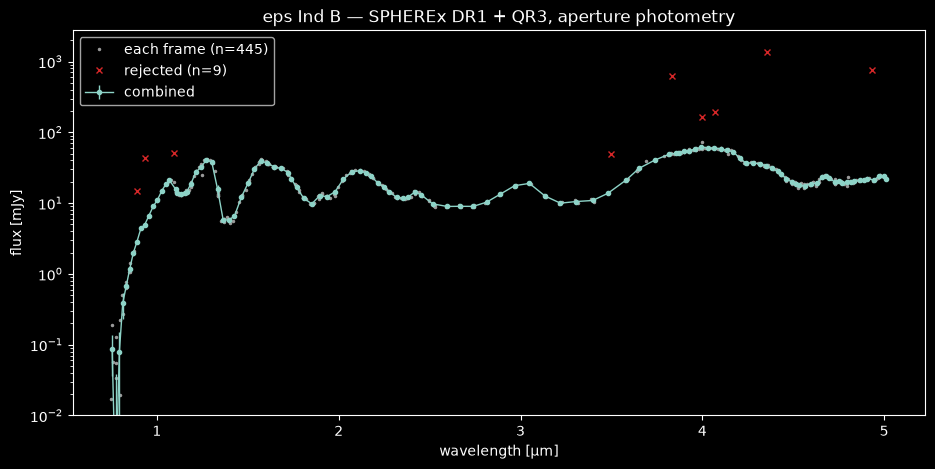

In [7]:
def reject_outliers(spec, n_sigma=5.0):
    """Drop a measurement if it is farther from the median of its neighbours (±1 bandwidth)
    than both the median itself (a factor ~2) and n_sigma times its own error."""
    lam, f = np.array(spec["lambda_um"]), np.array(spec["flux_mjy"])
    bw, err = np.array(spec["bandwidth_um"]), np.array(spec["err_mjy"])
    keep = np.ones(len(spec), bool)
    for i in range(len(spec)):
        near = np.abs(lam - lam[i]) < bw[i]
        if near.sum() >= 3:
            med = np.median(f[near])
            keep[i] = abs(f[i] - med) <= max(abs(med), n_sigma * err[i])
    return spec[keep], spec[~keep]


def combine(spec):
    """Mean of the measurements closer than half a bandwidth in λ; error from their scatter."""
    out, i = [], 0
    while i < len(spec):
        j = i
        while j + 1 < len(spec) and spec["lambda_um"][j + 1] - spec["lambda_um"][i] < 0.5 * spec["bandwidth_um"][i]:
            j += 1
        b = spec[i:j + 1]
        err = np.std(b["flux_mjy"], ddof=1) / np.sqrt(len(b)) if len(b) > 2 else np.max(b["err_mjy"])
        out.append(dict(lambda_um=float(np.mean(b["lambda_um"])), flux_mjy=float(np.mean(b["flux_mjy"])),
                        err_mjy=float(err), n=len(b)))
        i = j + 1
    return Table(rows=out)


clean, rejected = reject_outliers(spec)
comb = combine(clean)
print(f"{len(rejected)} outliers rejected; {len(comb)} points in the combined spectrum")

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(clean["lambda_um"], clean["flux_mjy"], ".", color="0.6", ms=3, label=f"each frame (n={len(clean)})")
ax.plot(rejected["lambda_um"], rejected["flux_mjy"], "x", color="tab:red", ms=5, label=f"rejected (n={len(rejected)})")
ax.errorbar(comb["lambda_um"], comb["flux_mjy"], comb["err_mjy"], fmt="o-", ms=3, lw=1, label="combined")
ax.set_yscale("log")
ax.set_ylim(0.01, None)
ax.set_xlabel("wavelength [µm]")
ax.set_ylabel("flux [mJy]")
ax.set_title(f"{TARGET} — SPHEREx DR1 + QR3, aperture photometry")
ax.legend()
plt.show()


9 outliers rejected; 117 points in the combined spectrum


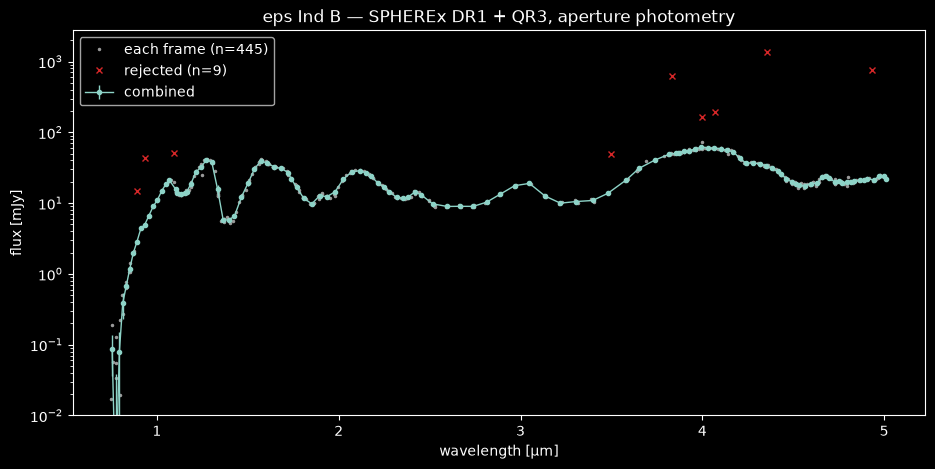

In [8]:
def reject_outliers(spec, n_sigma=5.0):
    """Drop a measurement if it is farther from the median of its neighbours (±1 bandwidth)
    than both the median itself (a factor ~2) and n_sigma times its own error."""
    lam, f = np.array(spec["lambda_um"]), np.array(spec["flux_mjy"])
    bw, err = np.array(spec["bandwidth_um"]), np.array(spec["err_mjy"])
    keep = np.ones(len(spec), bool)
    for i in range(len(spec)):
        near = np.abs(lam - lam[i]) < bw[i]
        if near.sum() >= 3:
            med = np.median(f[near])
            keep[i] = abs(f[i] - med) <= max(abs(med), n_sigma * err[i])
    return spec[keep], spec[~keep]


def combine(spec):
    """Mean of the measurements closer than half a bandwidth in λ; error from their scatter."""
    out, i = [], 0
    while i < len(spec):
        j = i
        while j + 1 < len(spec) and spec["lambda_um"][j + 1] - spec["lambda_um"][i] < 0.5 * spec["bandwidth_um"][i]:
            j += 1
        b = spec[i:j + 1]
        err = np.std(b["flux_mjy"], ddof=1) / np.sqrt(len(b)) if len(b) > 2 else np.max(b["err_mjy"])
        out.append(dict(lambda_um=float(np.mean(b["lambda_um"])), flux_mjy=float(np.mean(b["flux_mjy"])),
                        err_mjy=float(err), n=len(b)))
        i = j + 1
    return Table(rows=out)


clean, rejected = reject_outliers(spec)
comb = combine(clean)
print(f"{len(rejected)} outliers rejected; {len(comb)} points in the combined spectrum")

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(clean["lambda_um"], clean["flux_mjy"], ".", color="0.6", ms=3, label=f"each frame (n={len(clean)})")
ax.plot(rejected["lambda_um"], rejected["flux_mjy"], "x", color="tab:red", ms=5, label=f"rejected (n={len(rejected)})")
ax.errorbar(comb["lambda_um"], comb["flux_mjy"], comb["err_mjy"], fmt="o-", ms=3, lw=1, label="combined")
ax.set_yscale("log")
ax.set_ylim(0.01, None)
ax.set_xlabel("wavelength [µm]")
ax.set_ylabel("flux [mJy]")
ax.set_title(f"{TARGET} — SPHEREx DR1 + QR3, aperture photometry")
ax.legend()
plt.show()
